# Problem Set 1: Dynamic Programming on a Controlled Queue

**GitHub repository:** <https://github.com/Space0code/RLProblemSet1DynamicProgramming>

> **Disclaimer:** This lab was done by me (Tomi Božak). I implemented the environment and the algorithms, ran the experiments and wrote the interpretations myself. Claude Code was used for wider explanations of the theory and for support when I got stuck (debugging). It also helped with the notebook: the explanatory text, the extra plots and tables.

Solving a known MDP with **value iteration** and **policy iteration**.

- **Problem 1:** evaluate the *lazy* and *aggressive* policies.
- **Problem 2:** find the optimal policy with both methods, compare convergence and runtime, and compare the optimal policy with the basic ones.

| File | Contents |
|---|---|
| `QueueingEnvironment.py` | the MDP: `R[a, x]`, `P[a, x, y]`, `policy_model` |
| `QueueingPolicies.py` | policies, `evaluate_policy`, `q_values`, `greedy_policy`, `value_iteration`, `policy_iteration` |

## The MDP

| Part | Definition |
|---|---|
| States | queue length $x \in \{0, 1, \dots, N-1\}$, $N = 100$ |
| Actions | $a_\text{low}$ (service probability $q_\text{low} = 0.51$), $a_\text{high}$ ($q_\text{high} = 0.6$) |
| Reward | $r(x, a) = -(x/N)^2 - c(a)$, with $c(a_\text{low}) = 0$, $c(a_\text{high}) = 0.01$ |
| Transitions | $x_{t+1} = \text{trunc}(x_t + I_t - S_t)$, $\;\mathbb{P}[I_t = 1] = p = 0.5$, $\;\mathbb{P}[S_t = 1] = q(a_t)$ |
| Discount | $\gamma = 0.9$ |

Rewards are costs: long queues cost quadratically, and the fast server costs $0.01$ per step.

Arrival and service are independent, so the queue grows with probability $p\,(1 - q(a))$, shrinks with $(1 - p)\,q(a)$, and stays otherwise. `trunc` clips to $[0, N-1]$, so at the edges two outcomes land on the same state (hence `+=` in `P`).

## Setup

In [1]:
import os
import time

import numpy as np
import matplotlib.pyplot as plt

from QueueingEnvironment import QueueingEnvironment
from QueueingPolicies import (lazy_policy, aggressive_policy, evaluate_policy, q_values,
                              greedy_policy, value_iteration, policy_iteration)

FIG_DIR = "figures"                     
CHECKPOINTS = (1, 5, 10, 20, 50, 100)   

### Helpers

In [2]:
def plot_curves(curves, title, ylabel, filename):
    os.makedirs(FIG_DIR, exist_ok=True)
    plt.figure(figsize=(7, 4))
    for label, y in curves.items():
        plt.plot(y, label=label)
    plt.axhline(0, color="gray", lw=0.5)
    plt.xlabel("queue length x")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, filename), dpi=150)
    plt.show()


def plot_errors(curves, title, filename):
    os.makedirs(FIG_DIR, exist_ok=True)
    plt.figure(figsize=(7, 4))
    for label, err in curves.items():
        err = np.asarray(err, dtype=float)
        k = np.arange(1, len(err) + 1)
        style = {"ls": "--", "color": "gray"} if label.startswith("bound") else {}
        if np.count_nonzero(err > 0) < 10:
            style["marker"] = "o"                                    # short curves are easier to see with markers
        plt.semilogy(k, np.where(err > 0, err, np.nan), label=label, **style)   # exact 0 can't be drawn on a log axis
    plt.xlabel("iteration k")
    plt.ylabel("max_x |V_k(x) - V(x)|")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, filename), dpi=150)
    plt.show()


def fmt_states(states):
    states = list(states)
    if not states:
        return "none"
    runs, start = [], states[0]
    for prev, cur in zip(states[:-1], states[1:]):
        if cur != prev + 1:
            runs.append((start, prev))
            start = cur
    runs.append((start, states[-1]))
    return ", ".join(f"{a}" if a == b else f"{a}-{b}" for a, b in runs)

### A first look at the model

The **drift** $\mathbb{E}[x_{t+1} - x_t] = p\,(1 - q(a)) - (1 - p)\,q(a)$ is the expected change of the queue per step.

action   grow    shrink  stay    drift E[x' - x]   cost c(a)
LOW      0.245   0.255   0.500   -0.010            0.00
HIGH     0.200   0.300   0.500   -0.100            0.01


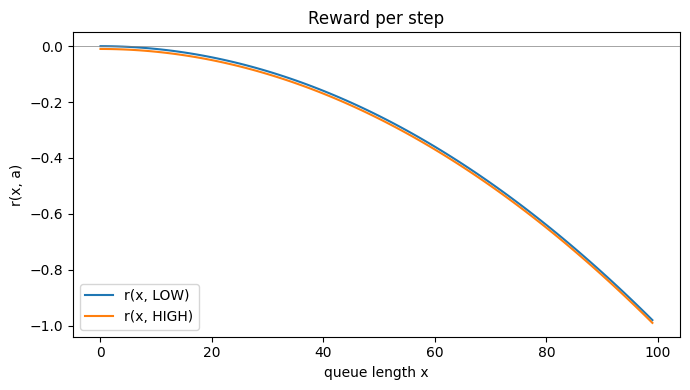

In [3]:
env = QueueingEnvironment()   # N = 100, used throughout the notebook

x = env.N // 2                # any interior state
print("action   grow    shrink  stay    drift E[x' - x]   cost c(a)")
for a, name in ((env.LOW, "LOW"), (env.HIGH, "HIGH")):
    grow, shrink, stay = env.P[a, x, x + 1], env.P[a, x, x - 1], env.P[a, x, x]
    print(f"{name:6s}   {grow:.3f}   {shrink:.3f}   {stay:.3f}   {grow - shrink:+.3f}            {env.cost[a]:.2f}")

plot_curves({"r(x, LOW)": env.R[env.LOW], "r(x, HIGH)": env.R[env.HIGH]},
            "Reward per step", "r(x, a)", "model_reward.png")

Both actions drain the queue on average: LOW barely, HIGH ten times faster for $0.01$ per step. The queue cost $(x/N)^2$ is tiny for short queues and dominates for long ones, so the better action depends on the state.

---
# Problem 1: Policy evaluation

> *Having evaluated the policies, plot the difference between the resulting value functions, $V^{\pi_\text{lazy}} - V^{\pi_\text{aggr}}$. Which policy is better in state 50? What about state 80?*

- **Lazy:** always $a_\text{low}$.
- **Aggressive:** $a_\text{low}$ for $x < 50$, $a_\text{high}$ for $x \ge 50$.

### Theory

$V^\pi(x) = \mathbb{E}\big[\sum_{t} \gamma^t r_t \mid x_0 = x\big]$. Rewards are costs, so values are negative and higher is better. For a fixed policy, $V^\pi$ solves the linear **Bellman expectation equation**

$$V^\pi = r^\pi + \gamma P^\pi V^\pi \quad\Longleftrightarrow\quad V^\pi = (I - \gamma P^\pi)^{-1} r^\pi,$$

which `evaluate_policy` solves directly in $O(N^3)$. The inverse exists because $\gamma < 1$ and $P^\pi$ is stochastic.

In [4]:
def problem1(env):
    V_lazy = evaluate_policy(env, lazy_policy(env))
    V_aggressive = evaluate_policy(env, aggressive_policy(env))
    diff = V_lazy - V_aggressive
    plot_curves({"V_lazy - V_aggr": diff}, "Problem 1", "value difference", "p1_lazy_minus_aggr.png")
    return V_lazy, V_aggressive, diff

**Sign convention:** `diff > 0` means lazy is better in that state, `diff < 0` means aggressive is better.

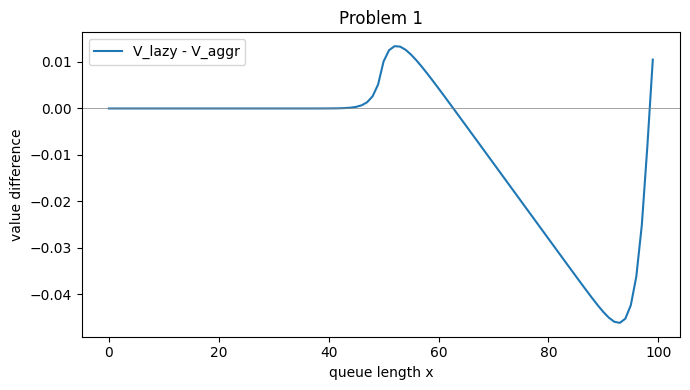

diff[50]: 0.010109901063741322 
diff[80]: -0.02799565826829653
      V_lazy   V_aggressive   diff
max  -0.003     -0.003       0.013
min  -9.582     -9.592       -0.046


In [5]:
V_lazy, V_aggressive, diff = problem1(env)
print("diff[50]:", diff[50], "\ndiff[80]:", diff[80])
print("      V_lazy   V_aggressive   diff")
print("max ", V_lazy.max().round(3), "   ", V_aggressive.max().round(3), "     ", diff.max().round(3))
print("min ", V_lazy.min().round(3), "   ", V_aggressive.min().round(3), "     ", diff.min().round(3))

### The value functions themselves

Values are of order $\frac{1}{1-\gamma} = 10$, while the policies differ by a few hundredths. That is why we compare differences.

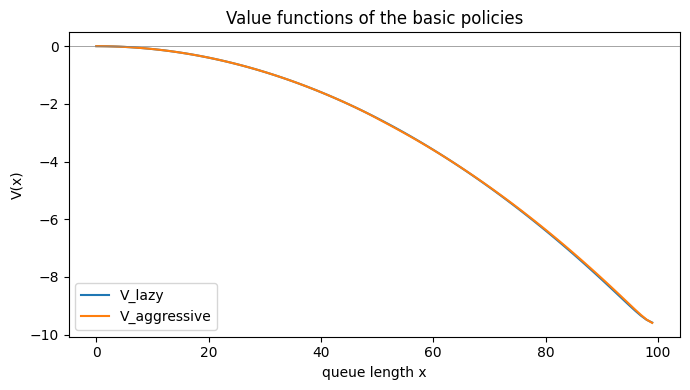

In [6]:
plot_curves({"V_lazy": V_lazy, "V_aggressive": V_aggressive},
            "Value functions of the basic policies", "V(x)", "p1_values.png")

### Cross-check: iterative policy evaluation

Iterating $V_{k+1} = r^\pi + \gamma P^\pi V_k$ from $V_0 = 0$ converges to the same $V^{\pi_\text{lazy}}$. The dashed line is the contraction bound $\gamma^k \max_x |V^\pi(x)|$.

max|V_k - V_lazy| after 150 iterations: 1.15e-06


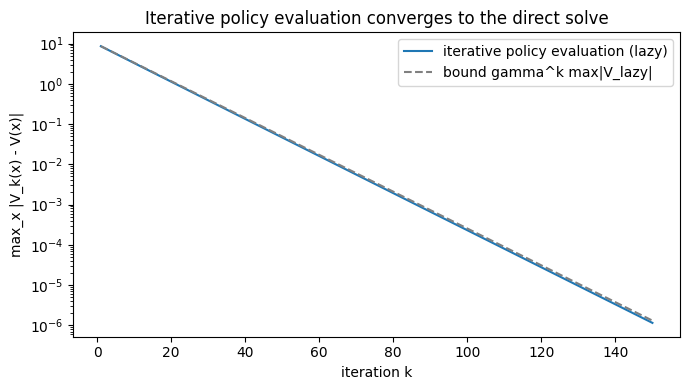

In [7]:
r_pi, P_pi = env.policy_model(lazy_policy(env))
V = np.zeros(env.N)
errors = []
for k in range(1, 151):
    V = r_pi + env.gamma * P_pi @ V
    errors.append(np.abs(V - V_lazy).max())

print(f"max|V_k - V_lazy| after 150 iterations: {errors[-1]:.2e}")
plot_errors({"iterative policy evaluation (lazy)": errors,
             "bound gamma^k max|V_lazy|": env.gamma ** np.arange(1, 151) * np.abs(V_lazy).max()},
            "Iterative policy evaluation converges to the direct solve", "p1_iterative_evaluation.png")

### Interpretation: Problem 1

**Which policy is better in state 50? In state 80? Why?**

At $x = 50$ lazy is better (diff $= +0.010$) and at $x = 80$ aggressive is better (diff $= -0.028$). That is because the queue cost $(x/N)^2$ rises quadratically, so one more request in the queue costs more the longer the queue already is. At 50 the queue cost is still small, so paying $0.01$ every step for the high service doesn't pay off yet. At 80 it does: aggressive empties the queue faster and in the longer run saves more than it pays.

Below 50 both policies do the same thing (LOW), so the difference there is almost 0. Lazy stays better up to $x = 62$, and from 63 on aggressive is better (the same state where the optimal policy starts using HIGH).

Around 95 the gap becomes smaller again, and at 99 lazy is even better. This is because of the $N = 100$ boundary (trunc), not because aggressive gets too expensive (its extra cost is always $0.01$). At the top the queue can't grow anymore, so the high service loses most of its benefit and only raises the chance to shrink from $0.255$ to $0.3$.

---
# Problem 2: Value Iteration and Policy Iteration

> *Plot the value functions produced by the two methods after 10, 20, 50, and 100 iterations! Which method converges faster to the optimal value function in terms of the number of iterations? What are the respective runtimes of performing 100 iterations with the two methods? What is your interpretation of these results?*

### Theory

$V^*$ solves the **Bellman optimality equation** $V^*(x) = \max_a Q^*(a, x)$, where $Q(a, x) = r(x, a) + \gamma \sum_y P(y \mid x, a)\, V(y)$ (`q_values`). The greedy policy with respect to $V^*$ (`greedy_policy`) is optimal.

- **Value iteration:** $V_{k+1}(x) = \max_a Q_k(a, x)$ from $V_0 = 0$. It is a $\gamma$-contraction, so the error is $\le \gamma^k \lVert V_0 - V^* \rVert_\infty$ and never exactly 0. One sweep costs $O(|A|\,N^2)$.
- **Policy iteration:** from the lazy policy, alternate exact evaluation (`evaluate_policy`, $O(N^3)$) and greedy improvement. Each new policy is at least as good (policy improvement theorem), and with finitely many policies it stops at the exact optimum.

"Value after $k$ iterations" is $V_k$ for value iteration and $V^{\pi_k}$ for policy iteration (iteration 1 gives $V^{\pi_\text{lazy}}$). `record_at` keeps copies of them in `snapshots`.

## Convergence of value iteration and policy iteration

Policy iteration's result is exact, so it serves as $V^*$.

In [8]:
def problem2_convergence(env):
    V_vi, V_history_vi = value_iteration(env, 100, record_at=CHECKPOINTS)
    V_star_pi, pi_star_pi, V_history_pi = policy_iteration(env, 100, record_at=CHECKPOINTS)

    V_star = V_star_pi
    pi_star = pi_star_pi

    plot_curves({f"VI k={k}": V_history_vi[k] for k in CHECKPOINTS} | {"V*": V_star},
                   "Value iteration", "V", "p2_vi.png")
    plot_curves({f"PI k={k}": V_history_pi[k] for k in CHECKPOINTS} | {"V*": V_star},
                   "Policy iteration", "V", "p2_pi.png")

    # Difference to V* after k iterations, per state (0 everywhere = converged)
    plot_curves({f"VI k={k}": V_history_vi[k] - V_star for k in CHECKPOINTS},
                "Value iteration: V_k - V*", "value difference", "p2_vi_minus_opt.png")
    plot_curves({f"PI k={k}": V_history_pi[k] - V_star for k in CHECKPOINTS},
                "Policy iteration: V_k - V*", "value difference", "p2_pi_minus_opt.png")

    # Error table: max_x |V_k(x) - V*(x)|
    print("   k   VI error    PI error")
    for k in CHECKPOINTS:
        err_vi = np.abs(V_history_vi[k] - V_star).max()
        err_pi = np.abs(V_history_pi[k] - V_star).max()
        print(f"{k:4d}   {err_vi:.3e}   {err_pi:.3e}")

    return V_star, pi_star

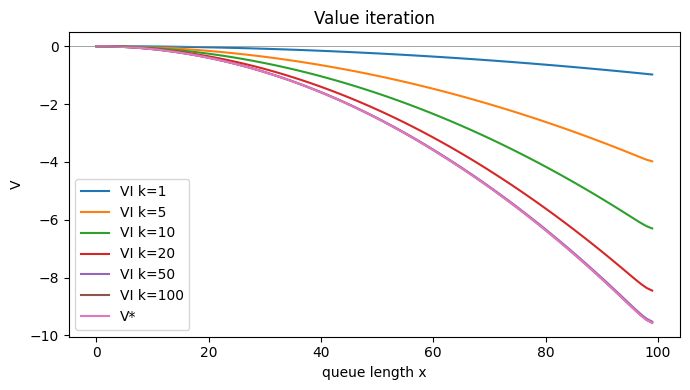

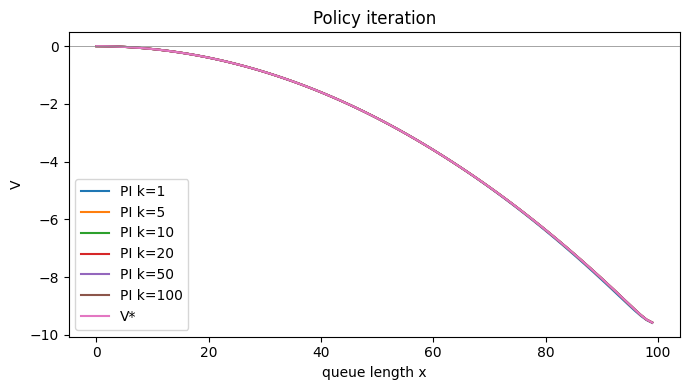

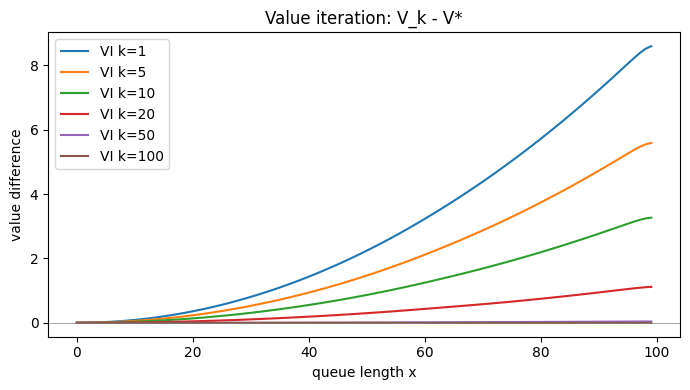

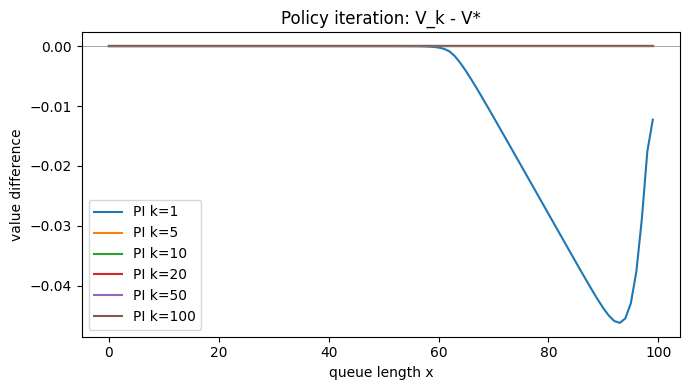

   k   VI error    PI error
   1   8.589e+00   4.622e-02
   5   5.586e+00   0.000e+00
  10   3.267e+00   0.000e+00
  20   1.117e+00   0.000e+00
  50   4.425e-02   0.000e+00
 100   2.042e-04   0.000e+00


In [9]:
V_star, pi_star = problem2_convergence(env)

### Error at every iteration

On a log scale a contraction is a straight line. The dashed line is the bound $\gamma^k \max_x |V^*(x)|$, and policy iteration's curve ends where its error is exactly 0.

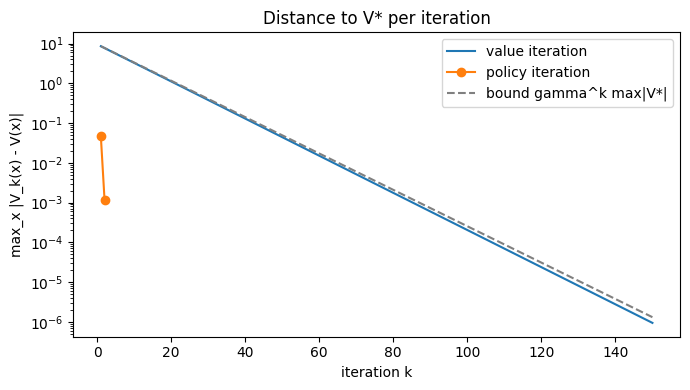

VI error ratio err_(k+1) / err_k (median): 0.8980   (gamma = 0.9)
VI sweeps until max|V_k - V*| < 1e-6: 150
PI iterations until V^pi_k == V* exactly: 3


In [10]:
K = 150
_, vi_all = value_iteration(env, K, record_at=range(1, K + 1))
_, _, pi_all = policy_iteration(env, K, record_at=range(1, K + 1))
err_vi = np.array([np.abs(vi_all[k] - V_star).max() for k in range(1, K + 1)])
err_pi = np.array([np.abs(pi_all[k] - V_star).max() for k in range(1, K + 1)])

plot_errors({"value iteration": err_vi,
             "policy iteration": err_pi,
             "bound gamma^k max|V*|": env.gamma ** np.arange(1, K + 1) * np.abs(V_star).max()},
            "Distance to V* per iteration", "p2_error_per_iteration.png")

print(f"VI error ratio err_(k+1) / err_k (median): {np.median(err_vi[1:] / err_vi[:-1]):.4f}   (gamma = {env.gamma})")
print(f"VI sweeps until max|V_k - V*| < 1e-6: {np.argmax(err_vi < 1e-6) + 1}")
print(f"PI iterations until V^pi_k == V* exactly: {np.argmax(err_pi == 0) + 1}")

### How the policy evolves

Policy iteration's policy after each improvement, and the first sweep from which value iteration's greedy policy is optimal. Policies settle long before values, because only the ranking of the two actions matters.

In [11]:
# Policy iteration, one iteration at a time
policy = lazy_policy(env)
print(" k   HIGH states after improvement   states changed   max|V^pi_k - V*|")
for k in range(1, 6):
    V = evaluate_policy(env, policy)
    new_policy = greedy_policy(env, V)
    high = np.where(new_policy == env.HIGH)[0]
    changed = np.sum(new_policy != policy)
    print(f"{k:2d}   {fmt_states(high):30s}  {changed:14d}   {np.abs(V - V_star).max():.3e}")
    policy = new_policy

# Value iteration: from which sweep on is greedy(V_k) optimal (and stays optimal)?
greedy_ok = np.array([(greedy_policy(env, vi_all[k]) == pi_star).all() for k in range(1, K + 1)])
optimal_from = K - np.argmin(greedy_ok[::-1]) + 1 if not greedy_ok.all() else 1
print(f"\nVI: greedy(V_k) is optimal for every k >= {optimal_from}, "
      f"while max|V_k - V*| there is still {err_vi[optimal_from - 1]:.2e}")

 k   HIGH states after improvement   states changed   max|V^pi_k - V*|
 1   62-97                                       36   4.622e-02
 2   63-98                                        2   1.158e-03
 3   63-98                                        0   0.000e+00
 4   63-98                                        0   0.000e+00
 5   63-98                                        0   0.000e+00

VI: greedy(V_k) is optimal for every k >= 40, while max|V_k - V*| there is still 1.30e-01


## Runtime of 100 iterations

One value-iteration sweep costs $O(|A|\,N^2)$ (`P @ V`), one policy-iteration step $O(N^3)$ (`np.linalg.solve`). Times are the best of 10 runs, because millisecond timings are noisy.

In [12]:
def best_time(f, repeats=10):
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        f()
        times.append(time.perf_counter() - t0)
    return min(times)


def problem2_runtime(sizes=(100, 300), n_iters=100):
    print(f"Runtime of {n_iters} iterations")
    print("    N   value iteration   policy iteration   PI / VI")
    for N in sizes:
        env_N = QueueingEnvironment(N=N)
        t_vi = best_time(lambda: value_iteration(env_N, n_iters))
        t_pi = best_time(lambda: policy_iteration(env_N, n_iters))
        print(f"{N:5d}   {t_vi:14.4f}s   {t_pi:15.4f}s   {t_pi / t_vi:7.1f}x")

In [13]:
problem2_runtime()

Runtime of 100 iterations
    N   value iteration   policy iteration   PI / VI


  100           0.0006s            0.0245s      41.8x


  300           0.0016s            0.1608s      99.2x


**Note:** the cost is $(x/N)^2$, so a larger $N$ makes each request cheaper and changes the optimal policy. Different $N$ are different problems, not just bigger ones.

In [14]:
for N in (100, 150, 200, 300):
    env_N = QueueingEnvironment(N=N)
    _, pi_N, _ = policy_iteration(env_N, 10)
    print(f"N = {N:3d}: optimal policy uses HIGH in states {fmt_states(np.where(pi_N == env_N.HIGH)[0])}")

N = 100: optimal policy uses HIGH in states 63-98
N = 150: optimal policy uses HIGH in states 140-144
N = 200: optimal policy uses HIGH in states none
N = 300: optimal policy uses HIGH in states none


### Interpretation: convergence and runtime

**Which method converges faster to the optimal value function in terms of the number of iterations?**

PI converges much faster. After 2 improvements the policy is already optimal, and from iteration 3 on its value is exactly $V^*$ (error 0). VI needs approx. 150 iterations to get within $10^{-6}$ of $V^*$ and never reaches it exactly, because its error only shrinks by about $\gamma = 0.9$ per iteration (at $k = 100$ it is still $2 \cdot 10^{-4}$). Its greedy policy is optimal from $k = 40$ though, way before the values converge.

**What are the runtimes of 100 iterations of each method, and what is your interpretation of these results?**

The runtime of 100 iterations is about 42x faster for value iteration at $N = 100$ (0.6 ms vs 24.5 ms), and about 99x faster at $N = 300$. One VI iteration is just a matrix-vector product, $O(N^2)$, while one PI iteration solves an $N \times N$ linear system, $O(N^3)$ (plus building $P^\pi$ in a python loop). So PI is much more expensive per iteration and the gap grows with $N$. Most of PI's 100 iterations are also wasted, since it has already converged after 3.

## Comparing the policies found by value iteration and policy iteration

`value_iteration` only returns values, so its policy is the greedy one with respect to its own final $V$. Using `V_star` instead would just give back `pi_star`. We compare the actions per state, and the exact value of that policy with $V^*$.

In [15]:
V_vi, _ = value_iteration(env, 100)          # VI's value after 100 sweeps
policy_vi = greedy_policy(env, V_vi)         # VI's policy: greedy w.r.t. its own V
policy_pi = pi_star                          # PI's policy

# 1. action by action
differ = np.where(policy_vi != policy_pi)[0]
print("same policy:", (policy_vi == policy_pi).all())
print("states where they differ:", fmt_states(differ))
print("HIGH states:", fmt_states(np.where(policy_vi == env.HIGH)[0]))

# 2. by value
V_policy_vi = evaluate_policy(env, policy_vi)  # exact value of VI's policy
print("max|V_vi - V*|          (VI's estimate):", np.abs(V_vi - V_star).max())
print("max|V^policy_vi - V*|   (VI's policy)  :", np.abs(V_policy_vi - V_star).max())

same policy: True
states where they differ: none
HIGH states: 63-98
max|V_vi - V*|          (VI's estimate): 0.0002042356148201918
max|V^policy_vi - V*|   (VI's policy)  : 0.0


## The optimal value function vs the basic policies

> *Plot the difference between the optimal value function and the value functions of the two policies evaluated in Problem 1, $V^* - V^{\pi_\text{lazy}}$ and $V^* - V^{\pi_\text{aggr}}$! Can you verify that $V^*$ strictly improves over these value functions? What is the optimal policy and how is it different from the basic ones evaluated in the first problem?*

$V^* \ge V^\pi$ holds in every state for every policy; the question is where it is strict. Gaps below about $10^{-14}$ are float noise, so the table counts gaps $> 10^{-12}$ as clearly positive.

In [16]:
def problem2_compare(env, V_star, pi_star, V_lazy, V_aggressive):
    basic = {"lazy": (lazy_policy(env), V_lazy),
             "aggressive": (aggressive_policy(env), V_aggressive)}

    # 1. action by action
    print("HIGH states, optimal   :", fmt_states(np.where(pi_star == env.HIGH)[0]))
    for name, (policy, _) in basic.items():
        print(f"HIGH states, {name:11s}:", fmt_states(np.where(policy == env.HIGH)[0]))
        print(f"  differs from optimal in:", fmt_states(np.where(policy != pi_star)[0]))

    # policy map: one row per policy, colour = action
    policies = {name: policy for name, (policy, _) in basic.items()} | {"optimal": pi_star}
    plt.figure(figsize=(7, 2.2))
    plt.imshow(np.array(list(policies.values())), aspect="auto", cmap="coolwarm", interpolation="nearest")
    plt.yticks(range(len(policies)), list(policies))
    plt.xlabel("queue length x")
    plt.title("Action per state (blue = LOW, red = HIGH)")
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, "p2_policies.png"), dpi=150)
    plt.show()

    # 2. by value: V* - V_pi >= 0 everywhere, and > 0 where pi* is strictly better
    plot_curves({f"V* - V_{name}": V_star - V for name, (_, V) in basic.items()},
                "Optimal vs basic policies", "value difference", "p2_opt_minus_basic.png")
    for name, (_, V) in basic.items():
        gap = V_star - V
        print(f"V* - V_{name}: min {gap.min():.3e} (at x={gap.argmin()}), "
              f"max {gap.max():.3e} (at x={gap.argmax()}), "
              f"x=50: {gap[50]:.3e}, x=80: {gap[80]:.3e}")
        print(f"  clearly > 0 (gap > 1e-12) in states: {fmt_states(np.where(gap > 1e-12)[0])}")

HIGH states, optimal   : 63-98
HIGH states, lazy       : none
  differs from optimal in: 63-98
HIGH states, aggressive : 50-99
  differs from optimal in: 50-62, 99


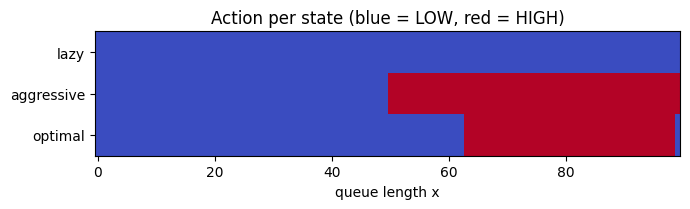

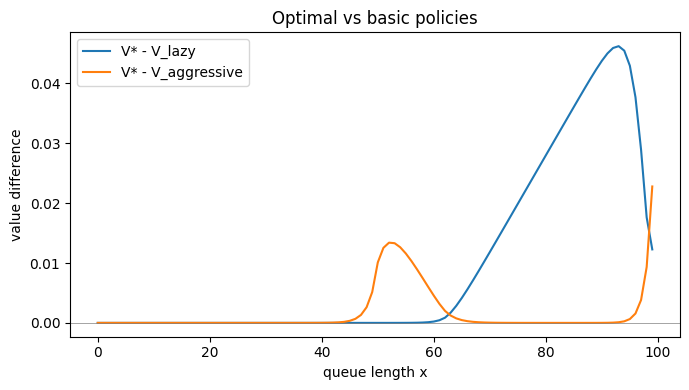

V* - V_lazy: min 0.000e+00 (at x=0), max 4.622e-02 (at x=93), x=50: 2.626e-07, x=80: 2.800e-02
  clearly > 0 (gap > 1e-12) in states: 32-99
V* - V_aggressive: min 3.426e-17 (at x=0), max 2.279e-02 (at x=99), x=50: 1.011e-02, x=80: 3.132e-07
  clearly > 0 (gap > 1e-12) in states: 16-99


In [17]:
problem2_compare(env, V_star, pi_star, V_lazy, V_aggressive)

On a log scale you can see how fast the gap fades away from the states where the policies disagree.

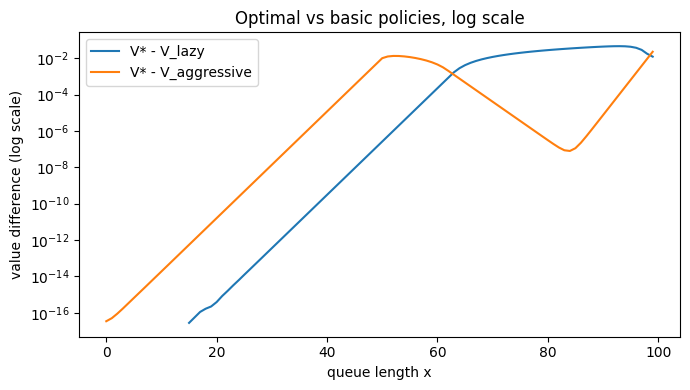

In [18]:
plt.figure(figsize=(7, 4))
for name, V in (("lazy", V_lazy), ("aggressive", V_aggressive)):
    gap = V_star - V
    plt.semilogy(np.where(gap > 0, gap, np.nan), label=f"V* - V_{name}")
plt.xlabel("queue length x")
plt.ylabel("value difference (log scale)")
plt.title("Optimal vs basic policies, log scale")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "p2_opt_minus_basic_log.png"), dpi=150)
plt.show()

### Interpretation: optimal policy

**Can you verify that $V^*$ strictly improves over $V^{\pi_\text{lazy}}$ and $V^{\pi_\text{aggr}}$? Where is the improvement strict?**

Yes. In the plot optimal vs basic policies the value difference is never negative, so $V^* \ge V^{\pi_\text{lazy}}$ and $V^* \ge V^{\pi_\text{aggr}}$ in every state (the smallest gaps are around $10^{-17}$, which is 0 up to float precision). The improvement is strict (gap clearly above float noise, $> 10^{-12}$) for $x \ge 32$ against lazy and $x \ge 16$ against aggressive. Below that the gap shrinks exponentially (straight line in the log plot), so in theory it is still positive, but too small to measure. It doesn't start at 50 because $V$ is an expectation over the future: from a state below the threshold you can still reach the states where the policies differ, it just gets less likely the further down you start.

**What is the optimal policy, and how is it different from the lazy and aggressive policies?**

The optimal policy uses HIGH in states 63-98 and LOW everywhere else. It is similar to aggressive, just activates later (63 instead of 50) and finishes earlier with the high service (LOW again at 99, because of trunc, see Problem 1). Lazy never uses HIGH, so it differs from the optimal policy in 63-98.

---
## Bonus: which method is faster when each stops at convergence?

Each method stops on its own instead of running 100 iterations:

- **Value iteration:** stop when $\lVert V_{k+1} - V_k \rVert_\infty < \varepsilon\,\frac{1-\gamma}{\gamma}$, which guarantees $\lVert V_{k+1} - V^* \rVert_\infty < \varepsilon = 10^{-6}$.
- **Policy iteration:** stop when the policy no longer changes.

At $N = 300$ the lazy policy is already optimal, so policy iteration stops after one iteration.

In [19]:
def vi_until_converged(env, eps=1e-6):
    V, k = np.zeros(env.N), 0
    while True:
        V_new = q_values(env, V).max(axis=0)
        k += 1
        if np.abs(V_new - V).max() < eps * (1 - env.gamma) / env.gamma:
            return V_new, k
        V = V_new


def pi_until_converged(env):
    policy, k = lazy_policy(env), 0
    while True:
        k += 1
        V = evaluate_policy(env, policy)
        new_policy = greedy_policy(env, V)
        if (new_policy == policy).all():
            return V, k
        policy = new_policy


print("    N   VI iterations   VI time    PI iterations   PI time    max|V_VI - V_PI|")
for N in (100, 300):
    env_N = QueueingEnvironment(N=N)
    V_vi_N, k_vi = vi_until_converged(env_N)
    V_pi_N, k_pi = pi_until_converged(env_N)
    t_vi = best_time(lambda: vi_until_converged(env_N))
    t_pi = best_time(lambda: pi_until_converged(env_N))
    print(f"{N:5d}   {k_vi:13d}   {t_vi:7.4f}s   {k_pi:13d}   {t_pi:7.4f}s   {np.abs(V_vi_N - V_pi_N).max():.1e}")

    N   VI iterations   VI time    PI iterations   PI time    max|V_VI - V_PI|
  100             150    0.0011s               3    0.0005s   9.4e-07
  300             153    0.0025s               1    0.0008s   9.4e-07


### Interpretation: bonus

**When each method stops at convergence, which one is faster, in iterations and in seconds? How does this change the conclusion from the 100-iteration runtimes?**

When each method stops by itself, PI is faster in iterations and in time. At $N = 100$ it needs 3 iterations vs 150 for VI and is about 2x faster (0.5 ms vs 1.1 ms). At $N = 300$ PI is about 3x faster, but there it only needs 1 iteration because the lazy starting policy is already optimal, so it's not really a fair comparison.

This changes the conclusion from the 100-iteration runtimes: VI is much cheaper per iteration, but PI needs so few iterations that it is faster overall. For bigger $N$ the $O(N^3)$ cost per PI iteration grows faster than VI's $O(N^2)$, so at some point VI should win again. The timings are in milliseconds, so they are a bit noisy.